<a href="https://colab.research.google.com/github/ushkgowda/Multi-Domain-Data-Analysis-Portfolio-5-Real--Projects/blob/main/project4_covid_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 4: COVID-19 Trends Analysis (Healthcare)
**Portfolio: Multi-Domain Data Analysis** | Domain: Healthcare / public health

**Goals:** analyze global and country COVID-19 trends: waves, case fatality over time, relationship between cases and deaths, and an India deep-dive.

**Data:** Johns Hopkins CSSE COVID-19 time series (confirmed cases and deaths, cumulative, by country), 22 Jan 2020 to 9 Mar 2023. These are reported confirmed cases, not true infections; testing and reporting changed greatly over time.

## 1. Setup and loading

In [1]:
import pandas as pd, numpy as np, warnings
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.signal import find_peaks
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

conf = pd.read_csv("/content/covid_confirmed_global.csv")
deaths = pd.read_csv("/content/covid_deaths_global.csv")
print(conf.shape, deaths.shape); conf.iloc[:3, :8]

(289, 1147) (289, 1147)


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0
1,NaN,Albania,41.15330,20.168300,0,0,0,0
2,NaN,Algeria,28.03390,1.659600,0,0,0,0


## 2. Data validation

In [2]:
NON = ["Diamond Princess", "MS Zaandam", "Summer Olympics 2020", "Winter Olympics 2022"]
dates = pd.to_datetime(conf.columns[4:], format="%m/%d/%y")
print("Rows aligned across files:", (conf[["Country/Region", "Province/State"]].fillna("") == deaths[["Country/Region", "Province/State"]].fillna("")).all().all())
print("Date range:", dates[0].date(), "to", dates[-1].date(), "| days:", len(dates), "| gaps:", int((pd.Series(dates).diff().dropna() != pd.Timedelta(days=1)).sum()))
print("Missing counts:", int(conf.iloc[:, 4:].isnull().sum().sum() + deaths.iloc[:, 4:].isnull().sum().sum()))
print("Non-country rows excluded:", conf["Country/Region"].isin(NON).sum())

def to_country(df):
    df = df[~df["Country/Region"].isin(NON)]
    out = df.groupby("Country/Region")[list(df.columns[4:])].sum().T; out.index = dates; return out
cc, dd = to_country(conf), to_country(deaths)
dc, ddd = cc.diff(), dd.diff(); dc.iloc[0], ddd.iloc[0] = cc.iloc[0], dd.iloc[0]
print("Countries:", cc.shape[1])
print("Negative daily case values:", int((dc < 0).sum().sum()), "in", int((dc < 0).any().sum()), "countries | net cases:", int(dc[dc < 0].sum().sum()))
print("Negative daily death values:", int((ddd < 0).sum().sum()))
print("Deaths > cases at some date:", list(dd.columns[(dd > cc).any()]))
print("No new cases in last 30 days:", int(((cc.iloc[-1] - cc.iloc[-31]) == 0).sum()), "countries")
mj = ddd.max().sort_values(ascending=False); print("Largest one-day death increase:", mj.index[0], int(mj.iloc[0]), ddd[mj.index[0]].idxmax().date())

Rows aligned across files: True
Date range: 2020-01-22 to 2023-03-09 | days: 1143 | gaps: 0
Missing counts: 0
Non-country rows excluded: 4
Countries: 197
Negative daily case values: 171 in 84 countries | net cases: -851329
Negative daily death values: 199
Deaths > cases at some date: ['Korea, North', 'Sudan', 'United Kingdom']
No new cases in last 30 days: 29 countries
Largest one-day death increase: China 59961 2023-01-15


Negative corrections are kept so totals stay exact. All trend work uses **7-day averages**, which also remove weekday reporting effects. No per-capita rates are computed because population data is not in the dataset.

## 3. Global overview

Total cases: 676,568,028 | deaths: 6,881,787 | deaths per 100 cases: 1.02
Peak daily cases (7-day avg): 2022-01-24 3,436,886
Peak daily deaths (7-day avg): 2021-01-26 14,855
1M cases: 2020-04-02
100M cases: 2021-01-25
500M cases: 2022-04-11
1M deaths: 2020-09-16
5M deaths: 2021-10-27


,cases,deaths,deaths_per_100_cases
2020,83777901.0,1901762.0,2.27
2021,204948804.0,3567242.0,1.74
2022,371734966.0,1224357.0,0.33
2023,16106357.0,188426.0,1.17


First 12 months: 15% of cases, 32% of deaths
2022 onward: 57% of cases, 21% of deaths


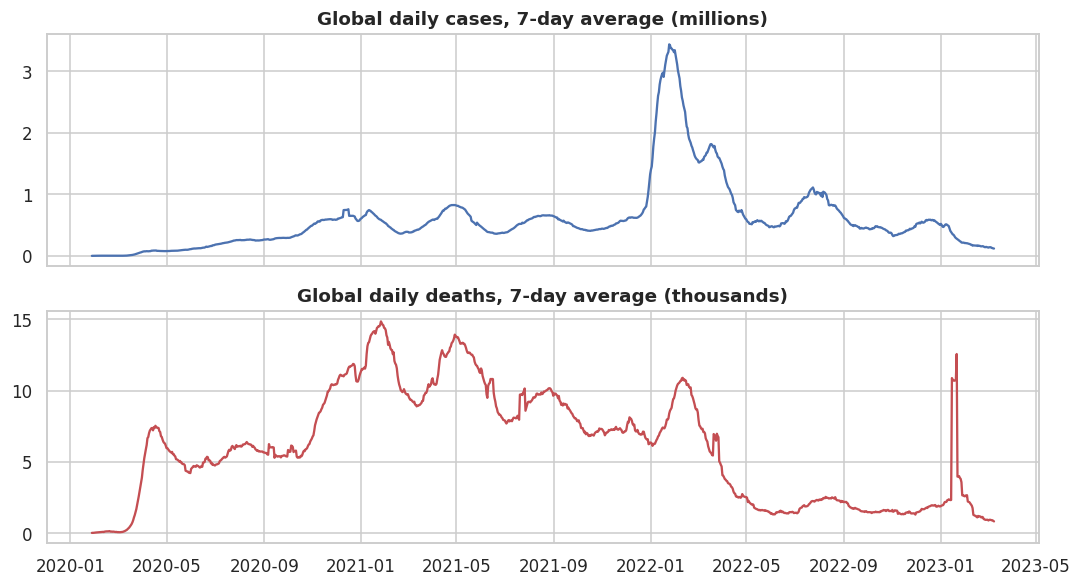

In [3]:
g, gd = cc.sum(axis=1), dd.sum(axis=1); gdc, gdd = dc.sum(axis=1), ddd.sum(axis=1)
sm = lambda s, w=7: s.rolling(w, min_periods=w).mean()
print("Total cases: %s | deaths: %s | deaths per 100 cases: %.2f" % (f"{g.iloc[-1]:,.0f}", f"{gd.iloc[-1]:,.0f}", gd.iloc[-1] / g.iloc[-1] * 100))
print("Peak daily cases (7-day avg):", sm(gdc).idxmax().date(), f"{sm(gdc).max():,.0f}")
print("Peak daily deaths (7-day avg):", sm(gdd).idxmax().date(), f"{sm(gdd).max():,.0f}")
for t in [1e6, 100e6, 500e6]: print(f"{t/1e6:.0f}M cases:", g[g >= t].index[0].date())
for t in [1e6, 5e6]: print(f"{t/1e6:.0f}M deaths:", gd[gd >= t].index[0].date())

yr = pd.DataFrame({"cases": gdc, "deaths": gdd}).groupby(gdc.index.year).sum(); yr["deaths_per_100_cases"] = (yr.deaths / yr.cases * 100).round(2); display(yr)
cut = pd.Timestamp("2021-01-22")
print("First 12 months: %.0f%% of cases, %.0f%% of deaths" % (gdc[:cut].sum() / gdc.sum() * 100, gdd[:cut].sum() / gdd.sum() * 100))
print("2022 onward: %.0f%% of cases, %.0f%% of deaths" % (gdc["2022-01-01":].sum() / gdc.sum() * 100, gdd["2022-01-01":].sum() / gdd.sum() * 100))

fig, axs = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axs[0].plot(sm(gdc) / 1e6, color="C0"); axs[0].set_title("Global daily cases, 7-day average (millions)")
axs[1].plot(sm(gdd) / 1e3, color="C3"); axs[1].set_title("Global daily deaths, 7-day average (thousands)")
plt.tight_layout(); plt.show()

In [4]:
# Delta-era vs Omicron-era peaks (global)
d_c, o_c = sm(gdc)["2021-04-01":"2021-10-31"], sm(gdc)["2022-01-01":"2022-04-30"]
d_d, o_d = sm(gdd)["2021-04-01":"2021-10-31"], sm(gdd)["2022-01-01":"2022-04-30"]
print("Cases peak: Delta-era %s (%s) vs Omicron %s (%s) -> %.1fx" % (f"{d_c.max():,.0f}", d_c.idxmax().date(), f"{o_c.max():,.0f}", o_c.idxmax().date(), o_c.max() / d_c.max()))
print("Deaths peak: Delta-era %s (%s) vs Omicron %s (%s) -> %.0f%%" % (f"{d_d.max():,.0f}", d_d.idxmax().date(), f"{o_d.max():,.0f}", o_d.idxmax().date(), o_d.max() / d_d.max() * 100))

Cases peak: Delta-era 826,677 (2021-04-28) vs Omicron 3,436,886 (2022-01-24) -> 4.2x
Deaths peak: Delta-era 13,926 (2021-04-29) vs Omicron 10,896 (2022-02-10) -> 78%


## 4. Country comparison

,cases,deaths,deaths_per_100,peak_cases,peak_date,waves
country,,,,,,
India,44690738,530779,1.19,391232.00,2021-05-08,3
US,103802702,1123836,1.08,806962.86,2022-01-15,4
Brazil,37076053,699276,1.89,189227.00,2022-01-29,7
United Kingdom,24658705,220721,0.90,197997.57,2022-02-01,5
France,39866718,166176,0.42,367017.29,2022-01-25,7
Germany,38249060,168935,0.44,229484.14,2022-03-24,4
Italy,25603510,188322,0.74,181821.71,2022-01-14,5
Russia,22075858,388478,1.76,188712.43,2022-02-15,4
Japan,33320438,72997,0.22,226955.00,2022-08-24,4


Top 10 share of cases: 59%
Deaths per 100 cases, countries with 1M+ cases (n=72):
lowest: {'Singapore': 0.08, 'Korea, South': 0.11, 'New Zealand': 0.11}
highest: {'Ecuador': 3.41, 'Mexico': 4.45, 'Peru': 4.89}


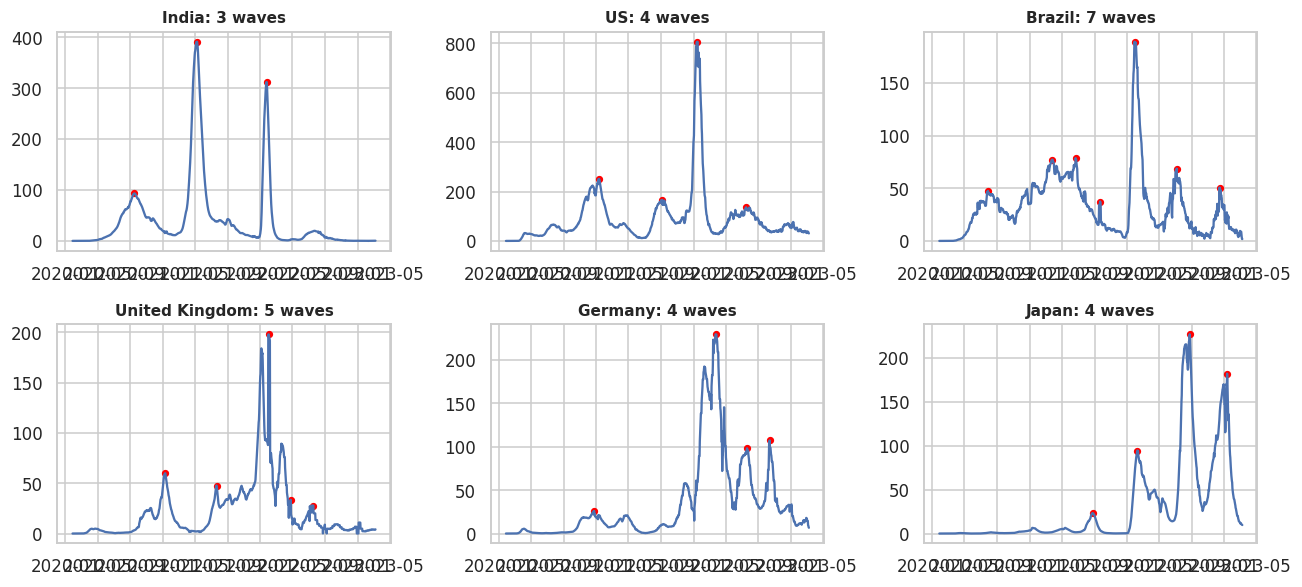

In [5]:
FOCUS = ["India", "US", "Brazil", "United Kingdom", "France", "Germany", "Italy", "Russia", "Japan", "South Africa"]
def waves(s7, prom=.08, dist=60):
    s = s7.fillna(0); return find_peaks(s.values, prominence=prom * s.max(), distance=dist)[0]
rows = []
for k in FOCUS:
    s = sm(dc[k]); pk = waves(s)
    rows.append(dict(country=k, cases=cc[k].iloc[-1], deaths=dd[k].iloc[-1], deaths_per_100=dd[k].iloc[-1] / cc[k].iloc[-1] * 100, peak_cases=s.max(), peak_date=s.idxmax().date(), waves=len(pk)))
display(pd.DataFrame(rows).set_index("country").round(2))

top = cc.iloc[-1].sort_values(ascending=False).head(10)
print("Top 10 share of cases: %.0f%%" % (top.sum() / cc.iloc[-1].sum() * 100))
cfr = (dd.iloc[-1] / cc.iloc[-1] * 100)[cc.iloc[-1] >= 1e6].sort_values()
print("Deaths per 100 cases, countries with 1M+ cases (n=%d):" % len(cfr)); print("lowest:", cfr.head(3).round(2).to_dict()); print("highest:", cfr.tail(3).round(2).to_dict())

fig, axs = plt.subplots(2, 3, figsize=(12, 5.5))
for ax, k in zip(axs.ravel(), ["India", "US", "Brazil", "United Kingdom", "Germany", "Japan"]):
    s = sm(dc[k]); pk = waves(s); ax.plot(s / 1e3); ax.scatter(s.index[pk], s.iloc[pk] / 1e3, color="red", s=14); ax.set_title(f"{k}: {len(pk)} waves", fontsize=10)
plt.tight_layout(); plt.show()

## 5. Early spread

In [6]:
rows = []
for k in FOCUS:
    s = cc[k]; i0 = np.where(s.values >= 100)[0][0]; y = np.log(s.values[i0:i0 + 15])
    rows.append(dict(country=k, date_100th_case=s.index[i0].date(), doubling_days=np.log(2) / stats.linregress(np.arange(len(y)), y).slope))
display(pd.DataFrame(rows).set_index("country").round(1))

,date_100th_case,doubling_days
country,,
India,2020-03-14,3.9
US,2020-03-04,2.3
Brazil,2020-03-13,2.7
United Kingdom,2020-03-02,2.9
France,2020-02-29,2.5
Germany,2020-03-01,2.6
Italy,2020-02-23,2.6
Russia,2020-03-17,3.3
Japan,2020-02-21,8.2


## 6. India deep-dive

,peak_date,peak_cases,window,cases,deaths_lag14,deaths_per_100,peak_deaths
wave,,,,,,,
1,2020-09-16,93198.57,2020-01-22 to 2021-02-11,10880603.0,156825.0,1.44,1166.57
2,2021-05-08,391232.00,2021-02-11 to 2021-12-18,23861900.0,325065.0,1.36,4190.00
3,2022-01-25,311982.14,2021-12-18 to 2022-02-18,8076456.0,33392.0,0.41,1130.86


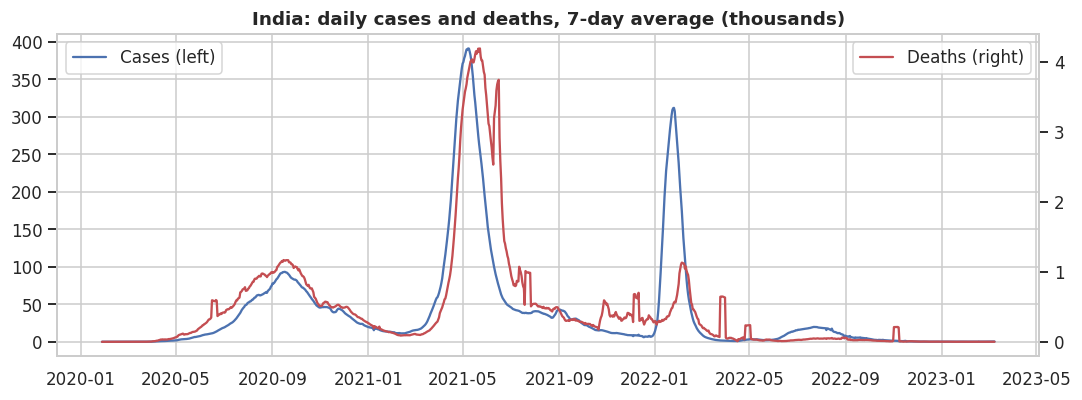

Wave 2 vs wave 3 deaths per 100 cases: 1.36% vs 0.41% (z-test p = 0.0e+00)
India share of global cases: 6.6%, deaths: 7.7%


In [7]:
s, d7 = sm(dc["India"]), sm(ddd["India"]); pk = waves(s); s0 = s.fillna(0)
last = pk[-1]; after = np.where(s0.values[last:] < 0.10 * s0.iloc[last])[0]; end_last = int(last + after[0]) if len(after) else len(s0) - 1
bounds = [0] + [int(s0.iloc[pk[i]:pk[i + 1]].values.argmin() + pk[i]) for i in range(len(pk) - 1)] + [end_last]
rows = []
for j, i in enumerate(pk):
    a, b = bounds[j], bounds[j + 1]; cases = dc["India"].iloc[a:b + 1].sum(); dths = ddd["India"].iloc[a + 14:min(b + 14, len(dd) - 1) + 1].sum()
    rows.append(dict(wave=j + 1, peak_date=s.index[i].date(), peak_cases=s.iloc[i], window=f"{s.index[a].date()} to {s.index[b].date()}", cases=cases, deaths_lag14=dths, deaths_per_100=dths / cases * 100,
                     peak_deaths=d7.iloc[i:i + 45].max()))
iw = pd.DataFrame(rows).set_index("wave"); display(iw.round(2))

fig, ax = plt.subplots(figsize=(10, 3.8)); ax.plot(s / 1e3, label="Cases (left)"); ax2 = ax.twinx(); ax2.plot(d7 / 1e3, color="C3", label="Deaths (right)"); ax2.grid(False)
ax.set_title("India: daily cases and deaths, 7-day average (thousands)"); ax.legend(loc="upper left"); ax2.legend(loc="upper right"); plt.tight_layout(); plt.show()
w = iw.reset_index(); p = (w.deaths_lag14[1] + w.deaths_lag14[2]) / (w.cases[1] + w.cases[2]); z = (w.deaths_per_100[1] - w.deaths_per_100[2]) / 100 / np.sqrt(p * (1 - p) * (1 / w.cases[1] + 1 / w.cases[2]))
print("Wave 2 vs wave 3 deaths per 100 cases: %.2f%% vs %.2f%% (z-test p = %.1e)" % (w.deaths_per_100[1], w.deaths_per_100[2], 2 * (1 - stats.norm.cdf(abs(z)))))
print("India share of global cases: %.1f%%, deaths: %.1f%%" % (cc["India"].iloc[-1] / cc.iloc[-1].sum() * 100, dd["India"].iloc[-1] / dd.iloc[-1].sum() * 100))

## 7. Case fatality over time

            Global  India    US    UK
2020-07-01    4.11   4.61  2.90  8.61
2020-12-01    1.81   1.15  1.26  1.97
2021-07-01    2.08   1.60  1.99  0.32
2022-01-31    0.40   0.50  0.39  0.16
2022-07-01    0.29   0.33  0.32  0.60
2023-02-01    1.08   0.62  0.95  1.62


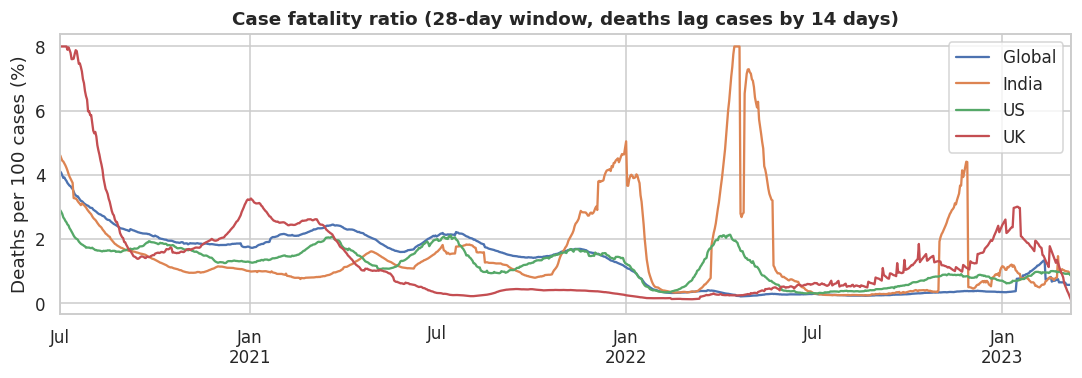

Monthly trend (Spearman): rho = -0.82, p = 6.4e-09


In [8]:
lagged = lambda c, d: d.rolling(28).sum() / c.rolling(28).sum().shift(14) * 100
lg = pd.DataFrame({"Global": lagged(gdc, gdd), "India": lagged(dc["India"], ddd["India"]), "US": lagged(dc["US"], ddd["US"]), "UK": lagged(dc["United Kingdom"], ddd["United Kingdom"])})
print(lg.loc[["2020-07-01", "2020-12-01", "2021-07-01", "2022-01-31", "2022-07-01", "2023-02-01"]].round(2))
ax = lg["2020-07-01":].clip(upper=8).plot(figsize=(10, 3.6)); ax.set_ylabel("Deaths per 100 cases (%)"); ax.set_title("Case fatality ratio (28-day window, deaths lag cases by 14 days)"); plt.tight_layout(); plt.show()
gm = lg["Global"].resample("ME").last().dropna(); gm = gm[gm.index >= "2020-07-01"]
print("Monthly trend (Spearman): rho = %.2f, p = %.1e" % stats.spearmanr(np.arange(len(gm)), gm.values))

## 8. Do deaths follow cases?

,best_lag_days,r_at_best,r_no_lag
Global,5.0,0.25,0.25
India,13.0,0.88,0.79
US,18.0,0.60,0.49
Brazil,9.0,0.55,0.54
United Kingdom,11.0,0.14,0.11
France,14.0,0.15,0.12
Germany,15.0,0.15,0.13
Italy,13.0,0.21,0.17
Russia,5.0,0.45,0.45
Japan,16.0,0.88,0.75


Median best lag across the 10 countries: 13.5


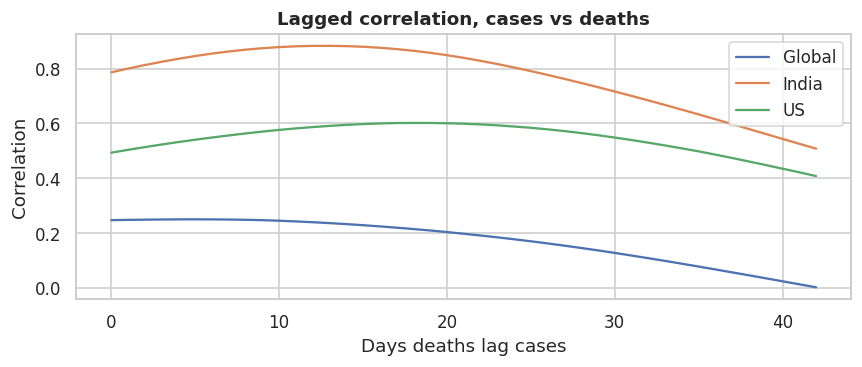

In [9]:
def best_lag(c7, d7):
    r = []
    for L in range(43):
        y = d7.shift(-L); ok = c7.notna() & y.notna(); r.append(np.corrcoef(c7[ok], y[ok])[0, 1])
    return r
res = {"Global": best_lag(sm(gdc), sm(gdd))}
for k in FOCUS: res[k] = best_lag(sm(dc[k]), sm(ddd[k]))
lagtab = pd.DataFrame({k: dict(best_lag_days=int(np.argmax(v)), r_at_best=max(v), r_no_lag=v[0]) for k, v in res.items()}).T.round(2); display(lagtab)
print("Median best lag across the 10 countries:", lagtab.drop("Global").best_lag_days.median())
plt.figure(figsize=(8, 3.5))
for k in ["Global", "India", "US"]: plt.plot(res[k], label=k)
plt.xlabel("Days deaths lag cases"); plt.ylabel("Correlation"); plt.legend(); plt.title("Lagged correlation, cases vs deaths"); plt.tight_layout(); plt.show()

## 9. Weekday reporting pattern

In [10]:
def weekday_ratio(x):
    r = (x / x.rolling(7, center=True).mean()).dropna(); r = r[np.isfinite(r)]; return pd.DataFrame({"r": r, "d": r.index.dayofweek})
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]; out = {}
for nm, x in [("Global", gdc), ("India", dc["India"]), ("US", dc["US"])]:
    w = weekday_ratio(x); out[nm] = w.groupby("d").r.mean().round(2).values
    print(nm, "Kruskal-Wallis p = %.1e" % stats.kruskal(*[g.r.values for _, g in w.groupby("d")]).pvalue)
display(pd.DataFrame(out, index=names))

Global Kruskal-Wallis p = 7.9e-129
India Kruskal-Wallis p = 3.5e-86
US Kruskal-Wallis p = 3.2e-99


,Global,India,US
Mon,0.92,0.82,1.03
Tue,1.08,0.91,1.03
Wed,1.13,1.10,1.32
Thu,1.16,1.09,1.22
Fri,1.12,0.95,1.22
Sat,0.84,1.10,0.61
Sun,0.72,0.97,0.50


## 10. Findings and recommendations

| Finding | Evidence |
|---|---|
| Two phases | first 12 months: 15% of cases, 32% of deaths; 2022 onward: 57% of cases, 21% of deaths |
| Omicron decoupled cases from deaths | 4.2x the Delta-era peak cases, 78% of its daily deaths |
| India: 3 waves | peaks Sep 2020, May 2021 (391k cases/day), Jan 2022; deaths per 100 cases 1.44%, 1.36%, 0.41% |
| Deaths trail cases ~2 weeks | median lag 14 days; India 13 days, r = 0.88 |
| Reporting artifacts | weekday dips, negative corrections, China's 60k one-day revision, 29 countries stopped updating |

**Recommendations:** (1) two-week early-warning rule; (2) track deaths and hospitalizations with cases; (3) plan surge capacity for variant peaks; (4) protect high-risk groups; (5) standardize reporting; (6) use 7-day averages; (7) add vaccination, hospitalization and excess-mortality data; (8) archive surveillance data.

**Limitations:** reported cases only, no per-capita rates, no vaccination or hospital data, wave counts depend on thresholds, p-values overstate certainty because daily data is autocorrelated.